# 🏡 Min-Max Normalization & PCA Workshop — OOP Version
**Course:** Machine Learning Programming (MLP)  
| Name | Student ID |
|------|------------|
| Juan Chirivi | 9115141 |
| Ricardo Mohammed | 7500382 |
| Zeynep | |
| Senay | |

This notebook follows the instructor's original normalization and PCA challenge while using classes from `workshop_analysis.py`. **All dependencies are listed in `requirements.txt`; there are no installation cells.**

## ❗ Why We Normalize: The Problem with Raw Feature Scales

In housing data, features like `Price` and `Lot_Size` can have values in the hundreds of thousands, while others like `Num_Bedrooms` range from 1 to 5. This creates problems when we use algorithms that depend on numeric magnitudes.

---

### ⚠️ What Goes Wrong Without Normalization

---

### 1. 🧭 K-Nearest Neighbors (KNN)

KNN uses the **Euclidean distance** formula:

$$
d = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2 + \cdots}
$$

**Example:**

- $ \text{Price}_1 = 650{,}000, \quad \text{Price}_2 = 250{,}000 $
- $ \text{Bedrooms}_1 = 3, \quad \text{Bedrooms}_2 = 2 $

Now compute squared differences:

$$
(\text{Price}_1 - \text{Price}_2)^2 = (650{,}000 - 250{,}000)^2 = (400{,}000)^2 = 1.6 \times 10^{11}
$$
$$
(\text{Bedrooms}_1 - \text{Bedrooms}_2)^2 = (3 - 2)^2 = 1
$$

➡️ **Price dominates the distance calculation**, making smaller features like `Bedrooms` irrelevant.

---

### 2. 📉 Linear Regression

Linear regression estimates:

$$
y = \beta_1 \cdot \text{Price} + \beta_2 \cdot \text{Bedrooms} + \beta_3 \cdot \text{Lot\_Size} + \epsilon
$$

If `Price` has very large values:
- Gradient updates for $ \beta_1 $ will be **much larger**
- Gradient updates for $ \beta_2 $ (Bedrooms) will be **very small**

➡️ The model overfits high-magnitude features like `Price`.

---

### 3. 🧠 Neural Networks

A single neuron computes:

$$
z = w_1 \cdot \text{Price} + w_2 \cdot \text{Bedrooms} + w_3 \cdot \text{Lot\_Size}
$$

If:

- $ \text{Price} = 650{,}000 $
- $ \text{Bedrooms} = 3 $
- $ \text{Lot\_Size} = 8{,}000 $

Then:

$$
z \approx w_1 \cdot 650{,}000 + w_2 \cdot 3 + w_3 \cdot 8{,}000
$$

➡️ Even with equal weights, `Price` contributes **most of the activation**, making it difficult for the network to learn from other features.

---

### ✅ Solution: Min-Max Normalization

We apply the transformation:

$$
x_{\text{normalized}} = \frac{x - x_{\text{min}}}{x_{\text{max}} - x_{\text{min}}}
$$

This scales all features to a common range (typically $[0, 1]$).

| Feature      | Raw Value | Min     | Max     | Normalized Value |
|--------------|-----------|---------|---------|------------------|
| Price        | 650,000   | 250,000 | 800,000 | 0.72             |
| Bedrooms     | 3         | 1       | 5       | 0.50             |
| Lot_Size     | 8,000     | 3,000   | 10,000  | 0.714            |

➡️ Now, **each feature contributes fairly** to model training or distance comparisons.

**Student clarification:** Large ranges can dominate distances. Different scales can also make gradient-based training harder, but they do not automatically mean that a regression model will *overfit*. In our PCA exercise, `Price` is treated as the target and is not used as a feature.

## 📌 Use Case: Housing Data
We are normalizing features from a real estate dataset to prepare it for machine learning analysis.

## Step 0 — Load and inspect the dataset using OOP

The `HousingDataset` class loads the real `housing_data.csv` provided for this workshop. We do not create random replacement data. 

**Repository Structure:**
- This notebook is located in the `notebooks/` folder.
- The OOP classes are in `src/workshop_analysis.py`.
- The dataset is in `data/housing_data.csv`.

The code below uses `..` to navigate up to the root directory to import the classes and load the data.

In [2]:
import sys
import os

sys.path.append(os.path.abspath(os.path.join("..", "src")))

from IPython.display import display
from workshop_analysis import (
    HousingDataset,
    ManualMinMaxNormalizer,
    HousingPCAAnalysis,
    WorkshopVisualizer,
)

# Create the object and use one of its methods to load the original data.
housing = HousingDataset("../data/housing_data.csv")
df = housing.load()
print(f"Housing dataset: {df.shape[0]} rows and {df.shape[1]} columns")
display(df.head())

Housing dataset: 2000 rows and 7 columns


,House_ID,Price,Area_sqft,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size
0,H100000,574507,1462,3,3,2002,4878
1,H100001,479260,1727,2,2,1979,4943
2,H100002,597153,1403,5,2,1952,5595
3,H100003,728454,1646,5,2,1992,9305
4,H100004,464876,853,1,1,1956,7407


In [3]:
# Ask the data object for a short data-quality report.
# We also count duplicate rows before we start preprocessing.
display(housing.quality_report())
print("Duplicate rows:", df.duplicated().sum())

,dtype,missing_values,unique_values
House_ID,str,0,2000
Price,int64,0,1991
Area_sqft,int64,0,1250
Num_Bedrooms,int64,0,5
Num_Bathrooms,int64,0,3
Year_Built,int64,0,73
Lot_Size,int64,0,1723


Duplicate rows: 0


**Observation:** This dataset has 2,000 houses and seven original columns, without missing values or duplicate rows. `House_ID` is just an identifier; we will not use it for PCA.

### 🔎 Step 1 — Implement Min-Max Normalization on the Housing Dataset

**Our OOP approach:** The `ManualMinMaxNormalizer` class calculates each column's minimum and maximum, applies the Min-Max formula manually using Pandas, and creates a new `_norm` column. No NumPy or Scikit-Learn scaling function is used. For a constant column (maximum equals minimum), the class safely assigns 0.0.

In [4]:
# These five columns are required by the professor's Step 1.
columns_to_normalize = [
    "Price", "Area_sqft", "Num_Bedrooms", "Num_Bathrooms", "Lot_Size"
]

# Create the normalization object, then execute its fit_transform() method.
normalizer = ManualMinMaxNormalizer(columns=columns_to_normalize)
df_norm = normalizer.fit_transform(df)

# View original and normalized values side by side.
display(normalizer.comparison(rows=5))

,Price,Price_norm,Area_sqft,Area_sqft_norm,Num_Bedrooms,Num_Bedrooms_norm,Num_Bathrooms,Num_Bathrooms_norm,Lot_Size,Lot_Size_norm
0,574507,0.485226,1462,0.315789,3,0.50,3,1.0,4878,0.320814
1,479260,0.387827,1727,0.394588,2,0.25,2,0.5,4943,0.326191
2,597153,0.508384,1403,0.298246,5,1.00,2,0.5,5595,0.380129
3,728454,0.642651,1646,0.370503,5,1.00,2,0.5,9305,0.687045
4,464876,0.373119,853,0.134701,1,0.00,1,0.0,7407,0.530030


In [5]:
# Check that every normalized column is inside the expected [0, 1] range.
normalization_checks = normalizer.validate()
display(normalization_checks)
assert normalization_checks["in_range_0_to_1"].all(), "Scaling validation failed"
print("All five features have been normalized successfully.")

,in_range_0_to_1
Price,True
Area_sqft,True
Num_Bedrooms,True
Num_Bathrooms,True
Lot_Size,True


All five features have been normalized successfully.


### 🔎 Talking Points #1 — Why normalization matters

1. **KNN and distance:** KNN uses distances to find similar records. A very large variable such as `Price` can influence the distance much more than the number of bedrooms, so normalization helps put features on a common range. When predicting price, we must not include `Price` itself as a KNN input.
2. **Gradient-based learning:** In some regression and neural-network training methods, large differences in feature scales can make learning slower or less stable. Min-Max normalization can make the optimization easier; it does not automatically improve every model.
3. **Housing features with different units:** Price is measured in money, size in square feet, and bedrooms in small counts. Scaling each of them to 0–1 makes magnitudes easier to compare. It does not make all features equally useful for prediction.

## 🧩 Challenge Extension: After Normalization, Which Features Matter Most?

You’ve normalized the housing features so they share a common scale.  
Now comes a common next step in ML workflows:

> **How do we identify the most important directions (principal components) in the data—and how might these relate to a target variable like `Price`?**

This introduces **Principal Component Analysis (PCA)**.

---

## 📚 PCA Theory (Conceptual)

### What PCA *is*
PCA is an **unsupervised** dimensionality reduction technique that:
- Finds **new axes** (principal components) that are **linear combinations** of your original features.
- Orders these axes so that:
  - **PC1** captures the **most variance** in the feature space,
  - **PC2** captures the next most variance, and so on,
  - Each PC is **orthogonal** (uncorrelated) with the previous ones.

### What PCA is *not*
PCA does **not** directly find features that “impact the target variable” because it does not use the target in its optimization.

However, you *can*:
- Compute PCs from the feature matrix **X** (after normalization),
- Then measure how PCs relate to the target **y** (e.g., correlation with `Price`, or a simple regression on PCs),
- Interpret which original features contribute most to PCs that are most related to **y**.

---

## 🧠 The Math (high level)
Given a centered feature matrix \(X\) (often standardized/normalized first):

1. Compute covariance matrix:
$$
\Sigma = \frac{1}{n-1}X^\top X
$$

2. Find eigenvectors (principal directions) and eigenvalues (variance captured):
$$
\Sigma v_i = \lambda_i v_i
$$

- $ v_i $ are **principal component directions** (loadings)
- $ \lambda_i $ are the **variance explained** by each component

---

## ✅ Why Normalize Before PCA?
PCA is sensitive to scale. Without normalization/standardization:
- A large-scale feature (e.g., `Price`) can dominate variance
- PCs will reflect units rather than structure

---

## 🎯 Student Challenge
Using the **housing dataset**:

1. Apply PCA to the normalized feature matrix \(X\) (exclude ID columns and the target).
2. Determine how many components are needed to explain **≥ 90%** of the variance.
3. Identify which original features contribute most to:
   - **PC1** and **PC2**, and
   - the **PC most correlated with the target** (`Price`).
4. Write a short interpretation:
   - “What does PC1 represent in housing terms?”
   - “Do the PCs that explain the most variance also relate most strongly to `Price`?”

### 🔗 How to Integrate This With Your Step 1 Normalization

- If you created normalized columns (e.g., `Area_sqft_norm`), use those in `candidate_features`.
- If you normalized in-place (overwriting original columns), you can use the original names.
- PCA should **not** include:
  - `House_ID` (identifier)
  - non-numeric categorical columns (unless encoded appropriately)
- Decide intentionally whether to include `Year_Built`:
  - It’s numeric, but it may behave differently than size/price-related features.

---

### ✅ Deliverable for the Challenge
Add a Markdown cell answering:

1. How many PCs explain at least **90%** variance?
2. Which features contribute most to **PC1** and **PC2**?
3. Which PC is most correlated with `Price`?
4. In plain language: what do you think PC1 represents?

### PCA plan — Sections A to F

We reuse the manual Min-Max results. **Input features:** normalized `Area_sqft`, `Num_Bedrooms`, `Num_Bathrooms`, and `Lot_Size`. **Target:** original `Price`, used only *after* fitting PCA to check correlations. We exclude `House_ID` because it is an ID, and omit `Year_Built` by choice to focus on the four workshop predictors. `HousingPCAAnalysis` is the OOP class for all PCA calculations; `WorkshopVisualizer` handles the charts.

### A — Choose the target and feature columns

In [6]:
# Choose the housing characteristics used for PCA.
# Price is the target, not a predictor in the PCA feature matrix.
predictor_features = ["Area_sqft", "Num_Bedrooms", "Num_Bathrooms", "Lot_Size"]
analysis = HousingPCAAnalysis(features=predictor_features, target="Price", threshold=0.90)
print("PCA input columns:", [f"{name}_norm" for name in predictor_features])
print("Target for later comparison: Price")

PCA input columns: ['Area_sqft_norm', 'Num_Bedrooms_norm', 'Num_Bathrooms_norm', 'Lot_Size_norm']
Target for later comparison: Price


### B — Check scaling before PCA

In [7]:
# Confirm that PCA will use the normalized columns created in Step 1.
# We reuse our manual Min-Max transformation; there is no second scaling method.
feature_cols = [f"{name}_norm" for name in predictor_features]
display(df_norm[feature_cols].agg(["min", "max"]).round(3))
assert all(df_norm[column].between(0, 1).all() for column in feature_cols)

,Area_sqft_norm,Num_Bedrooms_norm,Num_Bathrooms_norm,Lot_Size_norm
min,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0


### C — Fit PCA using the normalized predictors

In [8]:
# Fit PCA using our HousingPCAAnalysis object.
# PCA creates new axes, called principal components, from the four inputs.
pc_scores = analysis.fit(df_norm)
print("Number of components:", pc_scores.shape[1])
display(pc_scores.head().round(4))

Number of components: 4


,PC1,PC2,PC3,PC4
0,0.5159,-0.0234,-0.0845,-0.1111
1,0.0034,-0.2451,-0.0913,-0.0279
2,0.0436,0.5010,-0.0107,-0.1281
3,0.0450,0.4965,0.2849,-0.0184
4,-0.5087,-0.4763,0.1405,-0.2561


### D — Explore explained variance and the 90% goal

In [9]:
# Explained variance tells us how much of the variation each PC keeps.
variance_results = analysis.variance_table()
display(variance_results.round(4))

# Find the smallest number of PCs that explain at least 90% of the variance.
required_pcs = analysis.components_needed()
variance_preserved = variance_results.loc[required_pcs - 1, "cumulative_variance_ratio"]
print(f"Components needed for 90%: {required_pcs}")
print(f"Cumulative variance preserved: {variance_preserved:.2%}")

,component,explained_variance_ratio,cumulative_variance_ratio
0,PC1,0.4953,0.4953
1,PC2,0.3600,0.8554
2,PC3,0.0803,0.9356
3,PC4,0.0644,1.0000


Components needed for 90%: 3
Cumulative variance preserved: 93.56%


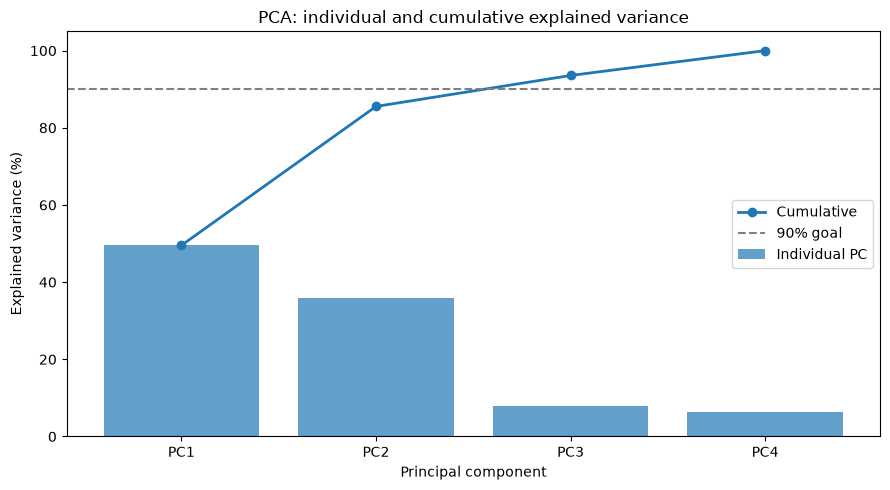

In [10]:
# Use the visualizer class to display individual and cumulative variance.
visuals = WorkshopVisualizer(analysis)
import matplotlib.pyplot as plt
fig = visuals.plot_explained_variance()
plt.show()

**Student interpretation:** The first PC captures the largest share of input variance. The cumulative line helps us see how many PCs we need for the 90% threshold. In this dataset, three PCs retain around 93.56%, so we can reduce four normalized predictors to three PCs while preserving most of their variance.

### E — Examine feature loadings and their contributions

In [11]:
# A loading tells us how much an original feature contributes to each PC.
# We compare absolute values to identify the strongest feature in each PC.
loadings = analysis.loading_table()
display(loadings.round(4))
print("Top PC1 feature:", analysis.strongest_feature("PC1"))
print("Top PC2 feature:", analysis.strongest_feature("PC2"))

,PC1,PC2,PC3,PC4
Area_sqft,0.0015,0.0174,-0.1236,0.9922
Num_Bedrooms,0.0534,0.9983,0.0203,-0.0151
Num_Bathrooms,0.9986,-0.0533,-0.0052,-0.0013
Lot_Size,0.0043,-0.0185,0.9921,0.1239


Top PC1 feature: Num_Bathrooms
Top PC2 feature: Num_Bedrooms


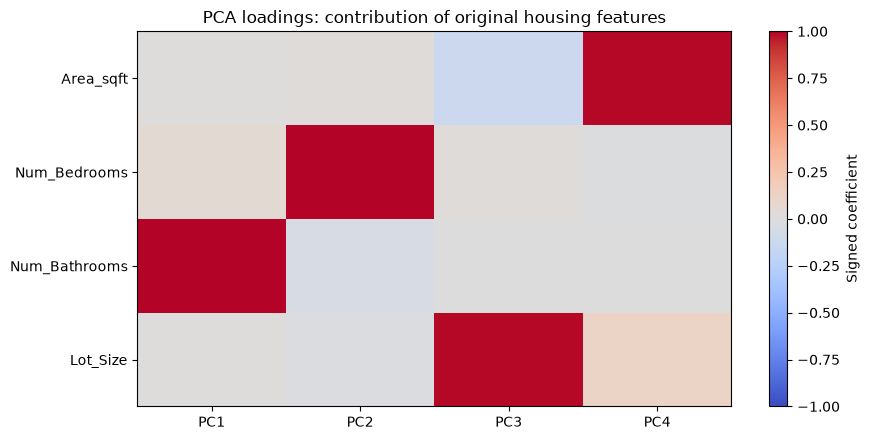

In [12]:
# Create a heatmap of signed loadings (feature contributions).
# Red/blue indicates direction; a larger absolute value means a stronger contribution.
fig = visuals.plot_loadings()
plt.show()

**Student interpretation:** PC1 is influenced most strongly by `Num_Bathrooms`, while PC2 is influenced most by `Num_Bedrooms` in these data. Each PC is a **combination** of features, not a new physical measurement. The sign of a PCA component can be flipped without changing its meaning, so absolute loading size is more useful for ranking contributions.

### F — Relate principal components to `Price`

In [13]:
# PCA was fitted without Price. Now compare every PC with Price using correlation.
# Correlation near zero means little linear relationship with the target.
correlations = analysis.correlation_table()
display(correlations.round(5))
related_pc, related_corr = analysis.most_price_related_pc()
print(f"Highest absolute Price correlation: {related_pc} ({related_corr:+.5f})")
print("Strongest original feature in this PC:", analysis.strongest_feature(related_pc))

,component,pearson_corr_with_price
0,PC1,-0.01140
1,PC2,-0.00542
2,PC3,0.01721
3,PC4,-0.01517


Highest absolute Price correlation: PC3 (+0.01721)
Strongest original feature in this PC: Lot_Size


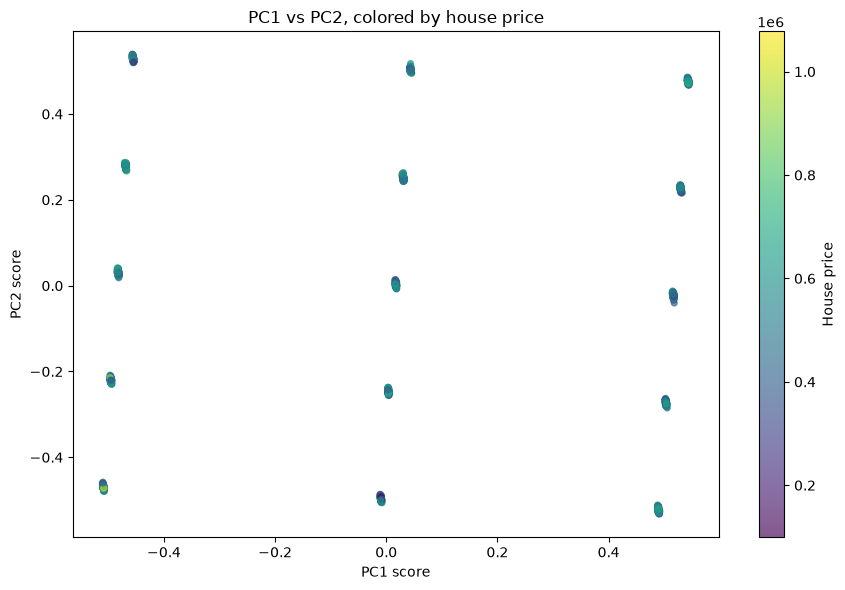

In [14]:
# Draw PC1 vs PC2 and color each house by its original Price.
# A clear price gradient would suggest a possible relationship with the target.
fig = visuals.plot_pc1_pc2()
plt.show()

### Answers to the instructor's PCA questions

1. **How many components explain at least 90% of variance?** **Three PCs**, which retain approximately **93.56%** of the variance in the four normalized predictors.
2. **Which variables contribute most to PC1 and PC2?** `Num_Bathrooms` has the highest absolute loading in **PC1**, while `Num_Bedrooms` has the highest absolute loading in **PC2**. Use the heatmap and loading table to see the other contributions.
3. **Which PC is most correlated with price?** **PC3**, at approximately **+0.017**, which is almost no linear relationship. Higher PCA variance does not mean higher target correlation.
4. **What does PC1 represent?** PC1 is mostly a direction connected to the number of bathrooms, together with some contribution from the other housing characteristics. It captures variation in the houses; we should not interpret it as a direct price predictor.

### 🔎 Talking Points #2 — Interpretation and implementation choices

1. **PCA only uses the predictors:** We intentionally keep `Price` outside PCA and compare it afterward. Otherwise, we could confuse information from the target with the housing characteristics we want to analyze.
2. **The 90% rule:** Three PCs are enough to capture about 93.56% of the total variance among four normalized features. This is a way to reduce dimensions while keeping most of the input variation, but it does not guarantee better predictions.
3. **Understanding loadings and price:** PC1 is mostly about bathroom-count variation, and PC2 is mostly about bedroom-count variation. The price correlations are close to zero, showing that high variance in the inputs does not necessarily reveal what predicts the target. Our OOP classes also separate loading, normalization, analysis, and plotting responsibilities.

## ✅ Workshop conclusion

We used `HousingDataset` to read the original housing CSV, `ManualMinMaxNormalizer` to scale five columns manually, `HousingPCAAnalysis` to apply PCA to four normalized predictors, and `WorkshopVisualizer` to create three charts. These classes make the notebook shorter, easier to read, and easier to reuse.

**What we learned:** Normalization helps features share a common 0–1 scale, while PCA finds new directions that summarize input variation. Three PCs preserved more than 90% of the variation, but their relationships with price were weak. PCA is useful for studying structure and reducing dimensions; it is not the same as selecting the best predictors of a target.

# 📤 How to Submit the Assignment

Follow these instructions carefully to ensure your team submits a complete and well-organized assignment.

## Step 1: Get the Starter Repository

1. Clone the GitHub repository provided by the instructor.
2. Keep the **original repository name**. Do **not** rename the repository.

## Step 2: Complete the Workshop

3. Create **one shared Jupyter Notebook** for the entire team to work on.
4. At the top of **`MinMax_Normalization_Workshop.ipynb`**, clearly include:
   - Team Number
   - Full Name of each team member
5. Complete **all coding tasks, analyses, and written answers** in the same notebook.
6. Make sure all notebook cells execute successfully before submission.

## Step 3: Update the Project Documentation

7. Replace the existing **`README.md`** file with a new version that:
   - Introduces your team
   - Explains the purpose of the workshop
   - Describes the work you completed
   - Summarizes your findings and conclusions
   - Can be used as the visual aid for your team's **5-minute presentation**

## Step 4: Review Project Dependencies

8. Review the project's Python dependencies and decide whether the **`requirements.txt`** file needs to be updated.
   - If you installed additional packages, regenerate or update the file.
   - If no new dependencies were added, no changes may be necessary.

## Step 5: Publish Your Work

9. Push the completed repository to your own GitHub account.
10. Verify that all files have been uploaded correctly and that the repository is publicly accessible if required by the instructor.

---

## ✅ Submission Checklist

Before submitting, confirm that the following items are complete:

- [ ] Repository name has not been changed
- [ ] `MinMax_Normalization_Workshop.ipynb` contains all required work
- [ ] Team number and team member names appear at the top of the notebook
- [ ] All questions have been answered
- [ ] All code runs successfully
- [ ] `README.md` has been replaced with a project summary
- [ ] README can support a 5-minute presentation
- [ ] `requirements.txt` has been reviewed and updated if necessary
- [ ] Repository has been pushed to your GitHub account
- [ ] Final work has been reviewed by all team members

> **Important:** Submit a repository that is clean, complete, and easy to understand. The notebook and README should clearly demonstrate your team's work, findings, and understanding of Min-Max Normalization.

**OOP submission note:** Although the instructor says the analyses should be shown in one shared notebook, the code itself is organized in `workshop_analysis.py`. Keep **both files** in the GitHub repository so the notebook can import the classes when the professor runs it. Install packages using `requirements.txt` outside the notebook if needed.